In [25]:
from pathlib import Path
import random

import numpy as np
import torch
from torch.utils.data import DataLoader

SEED = 42

# Fix random seeds to make experiments more reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Normal device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set paths for files
project_dir = Path.cwd()
data_dir = project_dir / "data" / "keras_slices_data"
checkpoint_dir = project_dir / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

# Setup constants
NUM_CLASSES = 6
PROSTATE_LABEL = 5 # Other labels can be found in dataset notebook
BATCH_SIZE = 16
# Value chosen after initial training split showed progress slowed after around 20 epochs.
# Also lines up with ~1h of training time for training restriction (A100 GPU)
EPOCHS = 20 

LEARNING_RATE = 1e-3

print("Device:", device)
print("Dataset:", data_dir)
print("Prostate label:", PROSTATE_LABEL)

Device: cuda
Dataset: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/data/keras_slices_data
Prostate label: 5


Split           Pairs   Patients
train           11460         31
validate          660          4
test              540          3
All image–mask pairs matched; no patient overlap.
Example: case_004_week_0_slice_0.nii.gz
Image: (256, 128) float32
Mask: (256, 128) int64
Normalised image mean: 0.0
Normalised image standard deviation: 1.0
Mask labels: [0 1 2 3]
Documentation files:
No documentation found beside the uploaded dataset.
Description: b''
Auxiliary information: b''
Extensions: Nifti1Extensions()
Training slices: 11460
Image batch: (16, 1, 256, 144) torch.float32
Mask batch: (16, 256, 144) torch.int64
Labels in this batch: [-100, 0, 1, 2, 3, 4, 5]


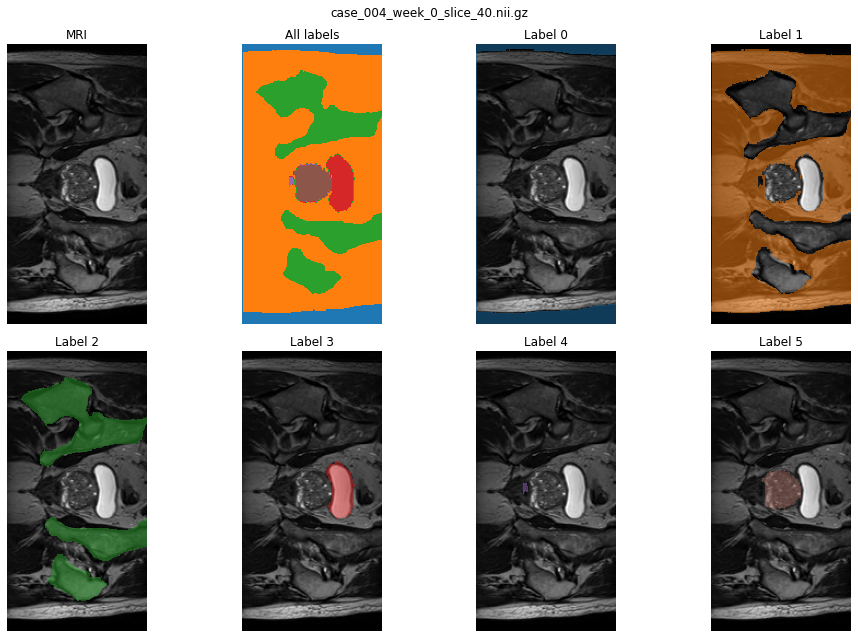

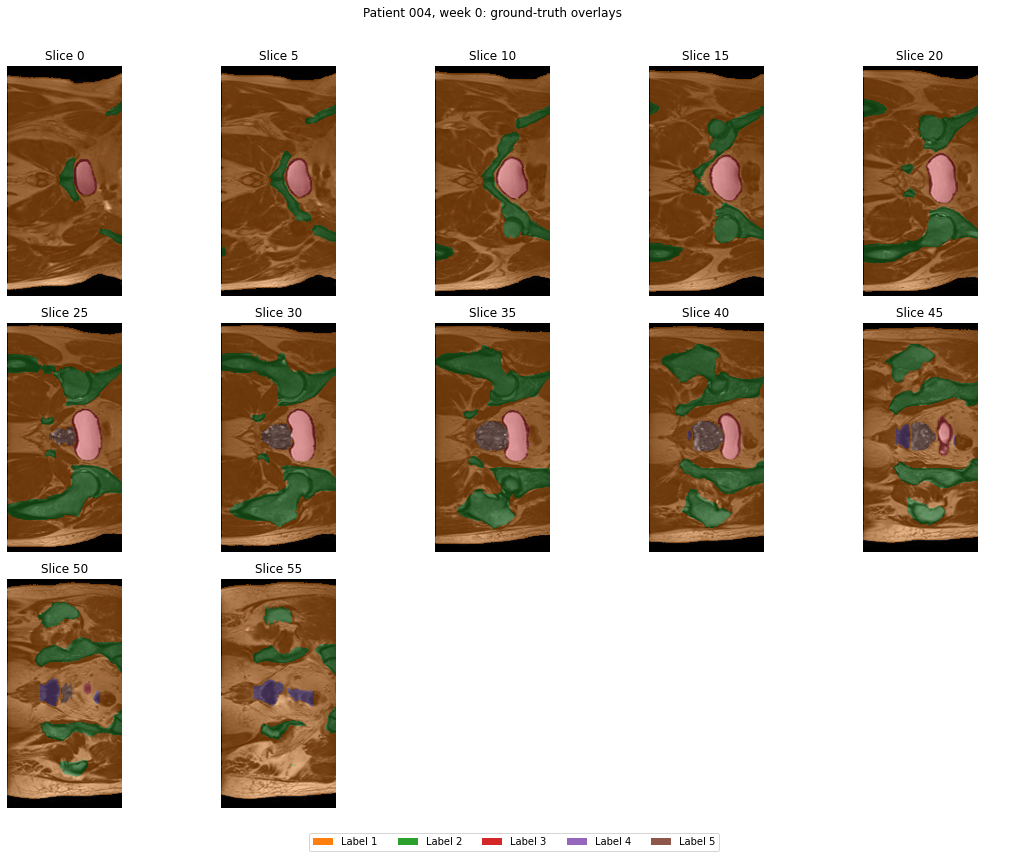

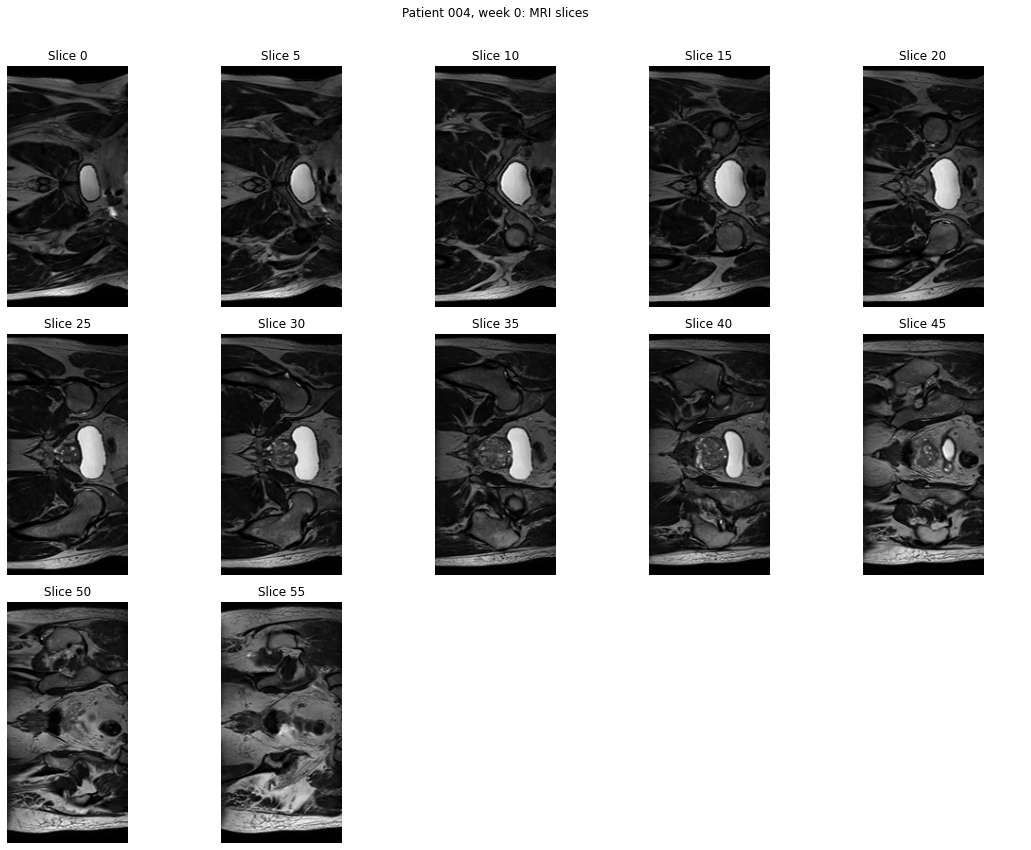

Device: cuda
Input shape: (16, 1, 256, 128)
Output shape: (16, 6, 256, 128)
Parameters: 2,158,502


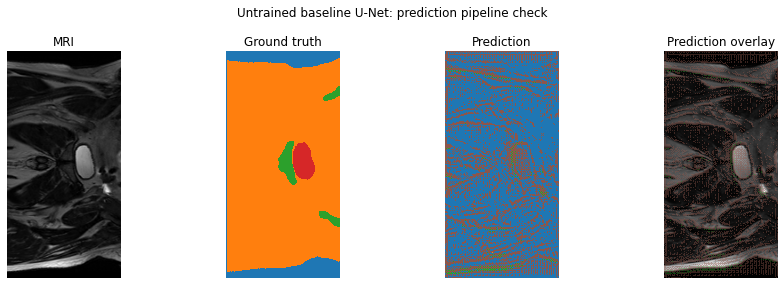

In [26]:
# Run dataset definitions and checks in this notebook's kernel.
%run ./dataset.ipynb

# Run the baseline architecture definitions.
%run ./modules.ipynb

In [27]:
# Re-establish settings after running the dataset and modules notebooks
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

data_dir = project_dir / "data" / "keras_slices_data"
splits = audit_splits(data_dir)

# Data loaders
# Shuffle only training data
train_loader = DataLoader(
    HipMRIDataset(splits["train"]),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    HipMRIDataset(splits["validate"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# Create fresh baseline
model = UNet(classes=NUM_CLASSES, base=16).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss(ignore_index=-100)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Prostate class:", PROSTATE_LABEL)

Split           Pairs   Patients
train           11460         31
validate          660          4
test              540          3
All image–mask pairs matched; no patient overlap.
Training batches: 717
Validation batches: 42
Prostate class: 5


In [ ]:
import time
import pandas as pd
from tqdm.auto import tqdm

# Ignore artificial padding added by the dataset loader.
criterion = torch.nn.CrossEntropyLoss(ignore_index=-100)


def run_epoch(model, loader, training=False):
    model.train(training)
    loss_sum, pixel_count = 0.0, 0
    intersection, predicted_count, target_count = 0, 0, 0

    # Limit progress-bar updates to avoid Jupyter message-rate warnings.
    for images, masks in tqdm(loader, leave=False, mininterval=5):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        # Validation calculates predictions without storing gradients.
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, masks)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss encountered")

            if training:
                loss.backward()
                optimizer.step()

        # Weight average loss by real pixels, excluding padding.
        valid = masks != -100
        pixels = valid.sum().item()
        loss_sum += loss.item() * pixels
        pixel_count += pixels

        # Accumulate prostate overlap across the entire epoch.
        prediction = logits.detach().argmax(dim=1)
        pred_prostate = (prediction == PROSTATE_LABEL) & valid
        true_prostate = (masks == PROSTATE_LABEL) & valid

        intersection += (pred_prostate & true_prostate).sum().item()
        predicted_count += pred_prostate.sum().item()
        target_count += true_prostate.sum().item()

    denominator = predicted_count + target_count
    dice = (
        2 * intersection / denominator
        if denominator > 0 else float("nan")
    )

    return loss_sum / pixel_count, dice

In [28]:
# Train the baseline
history = []
best_dice = -1.0

checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "baseline_best.pt"
history_path = checkpoint_dir / "baseline_history.csv"

# Start the clock measuring time budget for the training
TIME_LIMIT_SECONDS = 60 * 60
training_start = time.perf_counter()

# Track peak PyTorch GPU memory during training and validation.
if device.type == "cuda":
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_dice = run_epoch(
        model, train_loader, training=True
    )
    val_loss, val_dice = run_epoch(
        model, val_loader, training=False
    )

    seconds = time.perf_counter() - start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_prostate_dice": train_dice,
        "val_prostate_dice": val_dice,
        "seconds": seconds,
    })

    # Save the history before checking whether to stop.
    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_dice > best_dice:
        best_dice = val_dice

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_prostate_dice": val_dice,
            "num_classes": NUM_CLASSES,
            "prostate_label": PROSTATE_LABEL,
            "base": 16,
            "target_size": (256, 144),
            "model_type": "baseline",
        }, checkpoint_path)

    elapsed = time.perf_counter() - training_start

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"loss {train_loss:.4f} / {val_loss:.4f} | "
        f"prostate Dice {train_dice:.4f} / {val_dice:.4f} | "
        f"{seconds:.1f}s | best val {best_dice:.4f} | "
        f"elapsed {elapsed / 60:.1f} min",
        flush=True,
    )

    # Stop cleanly after finishing and recording the current epoch.
    if elapsed >= TIME_LIMIT_SECONDS:
        print("One-hour training limit reached. Stopping.")
        break

if device.type == "cuda":
    print(
        "Training/validation peak allocated VRAM:",
        f"{torch.cuda.max_memory_allocated(device) / 1024**3:.3f} GiB"
    )
    print(
        "Training/validation peak reserved VRAM:",
        f"{torch.cuda.max_memory_reserved(device) / 1024**3:.3f} GiB"
    )

print("Best checkpoint:", checkpoint_path)

Epoch 01/20 | loss 0.2285 / 0.1046 | prostate Dice 0.2869 / 0.6847 | 132.2s | best val 0.6847 | elapsed 2.2 min


Epoch 02/20 | loss 0.0611 / 0.0815 | prostate Dice 0.8221 / 0.7907 | 130.4s | best val 0.7907 | elapsed 4.4 min


Epoch 03/20 | loss 0.0506 / 0.0788 | prostate Dice 0.8589 / 0.7782 | 128.3s | best val 0.7907 | elapsed 6.5 min


Epoch 04/20 | loss 0.0477 / 0.0672 | prostate Dice 0.8717 / 0.8078 | 129.1s | best val 0.8078 | elapsed 8.7 min


Epoch 05/20 | loss 0.0431 / 0.0802 | prostate Dice 0.8861 / 0.8231 | 133.6s | best val 0.8231 | elapsed 10.9 min


...

Epoch 16/20 | loss 0.0402 / 0.0819 | prostate Dice 0.8908 / 0.8189 | 123.3s | best val 0.8231 | elapsed 34.5 min


Epoch 17/20 | loss 0.0406 / 0.0737 | prostate Dice 0.8919 / 0.8224 | 124.0s | best val 0.8231 | elapsed 36.6 min


Epoch 18/20 | loss 0.0376 / 0.0711 | prostate Dice 0.8987 / 0.8259 | 130.5s | best val 0.8259 | elapsed 38.8 min


Epoch 19/20 | loss 0.0405 / 0.0758 | prostate Dice 0.8919 / 0.7929 | 127.7s | best val 0.8259 | elapsed 40.9 min


Epoch 20/20 | loss 0.0390 / 0.0761 | prostate Dice 0.8941 / 0.8304 | 128.6s | best val 0.8304 | elapsed 43.1 min
Training/validation peak allocated VRAM: 0.727 GiB
Training/validation peak reserved VRAM: 0.906 GiB
Best checkpoint: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/baseline_best.pt


In [ ]:
# Epoch 20/20 | loss 0.0390 / 0.0761 | prostate Dice 0.8941 / 0.8304 | 128.6s | best val 0.8304 | elapsed 43.1 min
# Training/validation peak allocated VRAM: 0.727 GiB
#Training/validation peak reserved VRAM: 0.906 GiB
#Best checkpoint: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/baseline_best.pt

In [29]:
# Load the best saved weights before measuring inference.
checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Select 100 validation slices spread across the validation set.
indices = np.linspace(
    0, len(val_loader.dataset) - 1,
    num=min(100, len(val_loader.dataset)),
    dtype=int,
)

# Preload inputs so timing excludes disk access and preprocessing.
# Batch size 1 measures latency for one 2D slice.
inputs = [
    val_loader.dataset[int(i)][0].unsqueeze(0)
    for i in indices
]


def synchronise():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


times_ms = []

with torch.inference_mode():
    # Warm up the GPU before recording timings.
    warmup = inputs[0].to(device)
    for _ in range(10):
        _ = model(warmup).argmax(dim=1)

    synchronise()

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    for image in inputs:
        # Transfer before starting the timer: GPU inference only.
        image = image.to(device)
        synchronise()
        start = time.perf_counter()

        prediction = model(image).argmax(dim=1)

        synchronise()
        times_ms.append((time.perf_counter() - start) * 1000)

    # Release the final prediction and input references.
    del prediction, image, warmup

results = {
    "Model": checkpoint["model_type"],
    "Checkpoint epoch": checkpoint["epoch"],
    "Parameters": sum(p.numel() for p in model.parameters()),
    "Inference batch size": 1,
    "Slices measured": len(times_ms),
    "Mean inference time (ms/slice)": np.mean(times_ms),
    "Median inference time (ms/slice)": np.median(times_ms),
    "95th percentile time (ms/slice)": np.percentile(times_ms, 95),
}

if device.type == "cuda":
    results["Peak inference allocated VRAM (GiB)"] = (
        torch.cuda.max_memory_allocated(device) / 1024**3
    )
    results["Peak inference reserved VRAM (GiB)"] = (
        torch.cuda.max_memory_reserved(device) / 1024**3
    )

profile = pd.Series(results, name="Resource profile").to_frame()
display(profile)

# Keep measurements separately from the model weights.
profile.to_csv(checkpoint_dir / "baseline_resource_profile.csv")

,Resource profile
Model,baseline
Checkpoint epoch,20
Parameters,2158502
Inference batch size,1
Slices measured,100
Mean inference time (ms/slice),1.932159
Median inference time (ms/slice),1.932134
95th percentile time (ms/slice),1.951541
Peak inference allocated VRAM (GiB),0.129095
Peak inference reserved VRAM (GiB),0.908203


In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    checkpoint_dir / "baseline_best.pt",
    map_location=device,
    weights_only=False,  # Load only your own trusted checkpoint.
)

preview_model = UNet(
    classes=checkpoint["num_classes"],
    base=checkpoint["base"],
).to(device)

preview_model.load_state_dict(checkpoint["model_state_dict"])
preview_model.eval()

print("Loaded best baseline from epoch:", checkpoint["epoch"])
print("Validation prostate Dice:", checkpoint["val_prostate_dice"])

Loaded best baseline from epoch: 20
Validation prostate Dice: 0.8304243965853041


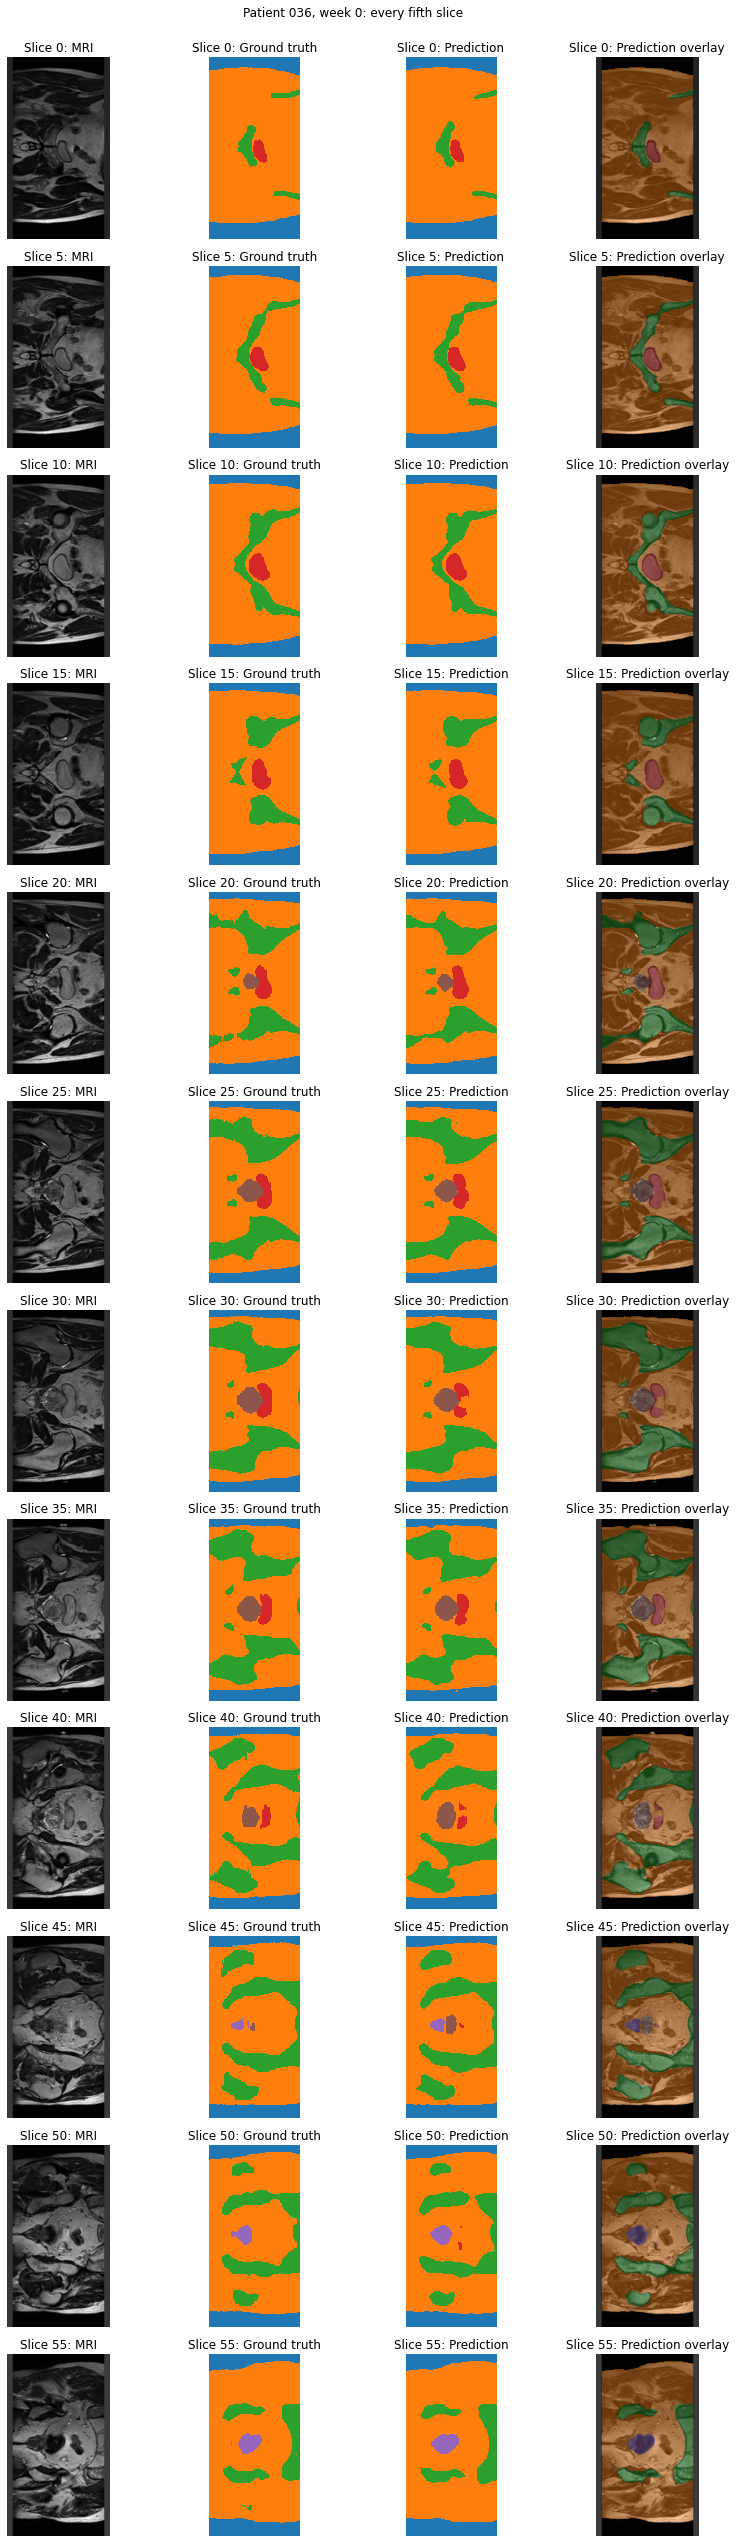

In [33]:
import matplotlib.pyplot as plt

PATIENT_ID = "036"  # Choose 036, 037, 038 or 039
WEEK = 0

# Select this patient's scan and sort slices numerically.
case_pairs = [
    pair for pair in splits["validate"]
    if pair[0].name.startswith(
        f"case_{PATIENT_ID}_week_{WEEK}_slice_"
    )
]
case_pairs.sort(
    key=lambda pair: int(pair[0].name.split("_slice_")[1].split(".")[0])
)

selected = case_pairs[::5]
assert selected, "No matching slices found."

# Reuse the dataset preprocessing, including padding.
preview_dataset = HipMRIDataset(selected)

fig, axes = plt.subplots(
    len(selected), 4,
    figsize=(12, 3 * len(selected)),
    squeeze=False,
)
colours = dict(cmap="tab10", vmin=0, vmax=9, interpolation="nearest")

preview_model.eval()

for row, (image_path, _) in enumerate(selected):
    image, mask = preview_dataset[row]
    slice_number = image_path.name.split("_slice_")[1].split(".")[0]

    with torch.no_grad():
        prediction = preview_model(image.unsqueeze(0).to(device))
        prediction = prediction.argmax(dim=1)[0].cpu().numpy()

    image = image[0].numpy()
    mask = mask.numpy()
    valid = mask != -100

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 1].imshow(np.ma.masked_where(~valid, mask), **colours)
    axes[row, 2].imshow(
        np.ma.masked_where(~valid, prediction), **colours
    )

    axes[row, 3].imshow(image, cmap="gray")
    axes[row, 3].imshow(
        np.ma.masked_where((prediction == 0) | ~valid, prediction),
        alpha=0.4,
        **colours,
    )

    for ax, title in zip(
        axes[row],
        ["MRI", "Ground truth", "Prediction", "Prediction overlay"],
    ):
        ax.set_title(f"Slice {slice_number}: {title}")
        ax.axis("off")

fig.suptitle(f"Patient {PATIENT_ID}, week {WEEK}: every fifth slice")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [34]:
from scipy.ndimage import binary_erosion, distance_transform_edt

# Calculate symmetric HD95 between the boundaries of two binary masks.
def calculate_hd95(predicted, reference):
    if not predicted.any() and not reference.any():
        return np.nan  # No structure present: boundary distance is undefined.

    if not predicted.any() or not reference.any():
        return np.inf  # A structure was completely missed or falsely predicted.

    predicted_boundary = predicted & ~binary_erosion(
        predicted, border_value=0
    )
    reference_boundary = reference & ~binary_erosion(
        reference, border_value=0
    )

    # Distance from every pixel to the closest boundary pixel.
    distance_to_reference = distance_transform_edt(~reference_boundary)
    distance_to_prediction = distance_transform_edt(~predicted_boundary)

    distances = np.concatenate([
        distance_to_reference[predicted_boundary],
        distance_to_prediction[reference_boundary],
    ])
    return float(np.percentile(distances, 95))


# Accumulate overlap counts across all validation slices.
intersections = np.zeros(NUM_CLASSES, dtype=np.int64)
predicted_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
reference_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
boundary_distances = [[] for _ in range(NUM_CLASSES)]

preview_model.eval()

with torch.inference_mode():
    for images, masks in tqdm(
        val_loader, desc="Validation metrics", mininterval=5
    ):
        predictions = (
            preview_model(images.to(device))
            .argmax(dim=1)
            .cpu()
            .numpy()
        )
        masks = masks.numpy()

        for prediction, reference in zip(predictions, masks):
            valid = reference != -100

            # Remove padding before extracting boundaries.
            rows, columns = np.where(valid)
            region = (
                slice(rows.min(), rows.max() + 1),
                slice(columns.min(), columns.max() + 1),
            )
            prediction = prediction[region]
            reference = reference[region]
            valid = valid[region]

            for label in range(NUM_CLASSES):
                predicted = (prediction == label) & valid
                actual = (reference == label) & valid

                intersections[label] += (predicted & actual).sum()
                predicted_counts[label] += predicted.sum()
                reference_counts[label] += actual.sum()
                boundary_distances[label].append(
                    calculate_hd95(predicted, actual)
                )

results = []

for label in range(NUM_CLASSES):
    intersection = intersections[label]
    denominator = predicted_counts[label] + reference_counts[label]
    union = denominator - intersection

    distances = np.asarray(boundary_distances[label])
    finite_distances = distances[np.isfinite(distances)]

    results.append({
        "Label": label,
        "Structure": LABEL_NAMES[label],
        "Dice": 2 * intersection / denominator if denominator else np.nan,
        "IoU": intersection / union if union else np.nan,
        "Mean HD95, finite slices (pixels)": (
            finite_distances.mean() if finite_distances.size else np.nan
        ),
        "Finite HD95 slices": int(np.isfinite(distances).sum()),
        "One mask empty (HD95 infinite)": int(np.isinf(distances).sum()),
        "Both masks empty (HD95 undefined)": int(np.isnan(distances).sum()),
    })

metrics = pd.DataFrame(results).set_index("Label")
display(metrics.round(4))

print("Prostate results:")
display(metrics.loc[[PROSTATE_LABEL]].round(4))

metrics.to_csv(checkpoint_dir / "isensse_validation_metrics.csv")

Validation metrics: 100%|██████████| 42/42 [00:30<00:00,  1.38it/s]


,Structure,Dice,IoU,"Mean HD95, finite slices (pixels)",Finite HD95 slices,One mask empty (HD95 infinite),Both masks empty (HD95 undefined)
Label,,,,,,,
0,Outside body,0.9943,0.9887,0.5136,660,0,0
1,Remaining tissue,0.9825,0.9656,2.7765,660,0,0
2,Bone,0.9367,0.8809,6.4502,660,0,0
3,Bladder,0.8706,0.7708,4.7429,455,26,179
4,Rectum,0.8914,0.8041,5.0969,243,14,403
5,Prostate,0.8304,0.7100,4.3941,237,43,380


Prostate results:


,Structure,Dice,IoU,"Mean HD95, finite slices (pixels)",Finite HD95 slices,One mask empty (HD95 infinite),Both masks empty (HD95 undefined)
Label,,,,,,,
5,Prostate,0.8304,0.71,4.3941,237,43,380


In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from scipy.ndimage import binary_erosion, distance_transform_edt
from tqdm.auto import tqdm

# ---------------------------------------------------------
# 1. Select the model and its best checkpoint.
# ---------------------------------------------------------

# BASELINE — use these settings in the baseline notebook:
MODEL_NAME = "baseline"
MODEL_CLASS = UNet
CHECKPOINT = project_dir / "checkpoints" / "baseline_best.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

# Load only your own trusted checkpoint.
checkpoint = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=False
)

test_model = MODEL_CLASS(
    classes=checkpoint["num_classes"],
    base=checkpoint["base"],
)
test_model.load_state_dict(checkpoint["model_state_dict"])
test_model = test_model.to(device).eval()

num_classes = checkpoint["num_classes"]
target_size = tuple(checkpoint["target_size"])
prostate_label = checkpoint["prostate_label"]

print("Model:", MODEL_NAME)
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation Dice:", checkpoint["val_prostate_dice"])

# Release the checkpoint's optimiser tensors.
del checkpoint

# ---------------------------------------------------------
# 2. Load the same held-out test split for every model.
# ---------------------------------------------------------

test_dataset = HipMRIDataset(
    splits["test"],
    target_size=target_size,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

label_names = {
    0: "Outside body",
    1: "Remaining tissue",
    2: "Bone",
    3: "Bladder",
    4: "Rectum",
    5: "Prostate",
}

print("Test slices:", len(test_dataset))

# ---------------------------------------------------------
# 3. Define the same HD95 calculation for every model.
# ---------------------------------------------------------

def test_hd95(predicted, reference):
    if not predicted.any() and not reference.any():
        return np.nan

    if not predicted.any() or not reference.any():
        return np.inf

    predicted_boundary = predicted & ~binary_erosion(
        predicted, border_value=0
    )
    reference_boundary = reference & ~binary_erosion(
        reference, border_value=0
    )

    distance_to_reference = distance_transform_edt(
        ~reference_boundary
    )
    distance_to_prediction = distance_transform_edt(
        ~predicted_boundary
    )

    distances = np.concatenate([
        distance_to_reference[predicted_boundary],
        distance_to_prediction[reference_boundary],
    ])
    return float(np.percentile(distances, 95))

# ---------------------------------------------------------
# 4. Evaluate predictions without updating model weights.
# ---------------------------------------------------------

intersections = np.zeros(num_classes, dtype=np.int64)
predicted_counts = np.zeros(num_classes, dtype=np.int64)
reference_counts = np.zeros(num_classes, dtype=np.int64)
slice_records = []
sample_index = 0

with torch.inference_mode():
    for images, masks in tqdm(
        test_loader, desc=f"Testing {MODEL_NAME}", mininterval=5
    ):
        predictions = (
            test_model(images.to(device))
            .argmax(dim=1)
            .cpu()
            .numpy()
        )
        masks = masks.numpy()

        for prediction, reference in zip(predictions, masks):
            image_path = Path(splits["test"][sample_index][0])
            sample_index += 1

            # Crop away the artificial padding before measuring boundaries.
            valid = reference != -100
            rows, columns = np.where(valid)
            region = (
                slice(rows.min(), rows.max() + 1),
                slice(columns.min(), columns.max() + 1),
            )
            prediction = prediction[region]
            reference = reference[region]
            valid = valid[region]

            for label in range(num_classes):
                predicted = (prediction == label) & valid
                actual = (reference == label) & valid

                intersection = int((predicted & actual).sum())
                predicted_count = int(predicted.sum())
                reference_count = int(actual.sum())

                intersections[label] += intersection
                predicted_counts[label] += predicted_count
                reference_counts[label] += reference_count

                denominator = predicted_count + reference_count
                union = denominator - intersection

                slice_records.append({
                    "model": MODEL_NAME,
                    "file": image_path.name,
                    "patient": image_path.name.split("_")[1],
                    "label": label,
                    "structure": label_names[label],
                    "dice": (
                        2 * intersection / denominator
                        if denominator else np.nan
                    ),
                    "iou": intersection / union if union else np.nan,
                    "hd95_pixels": test_hd95(predicted, actual),
                    "false_negative_pixels": int(
                        (actual & ~predicted).sum()
                    ),
                    "false_positive_pixels": int(
                        (predicted & ~actual).sum()
                    ),
                    "missed_structure": (
                        reference_count > 0 and predicted_count == 0
                    ),
                    "false_structure": (
                        reference_count == 0 and predicted_count > 0
                    ),
                    "both_empty": denominator == 0,
                })

# ---------------------------------------------------------
# 5. Summarise pooled overlap and per-slice boundary distances.
# ---------------------------------------------------------

slice_metrics = pd.DataFrame(slice_records)
summary = []

for label in range(num_classes):
    subset = slice_metrics[slice_metrics["label"] == label]
    distances = subset["hd95_pixels"].to_numpy()
    finite = distances[np.isfinite(distances)]

    denominator = predicted_counts[label] + reference_counts[label]
    union = denominator - intersections[label]

    summary.append({
        "Label": label,
        "Structure": label_names[label],
        "Dice": (
            2 * intersections[label] / denominator
            if denominator else np.nan
        ),
        "IoU": (
            intersections[label] / union if union else np.nan
        ),
        "Mean finite HD95 (pixels)": (
            finite.mean() if finite.size else np.nan
        ),
        "Finite HD95 slices": int(np.isfinite(distances).sum()),
        "Missed structure slices": int(subset["missed_structure"].sum()),
        "False structure slices": int(subset["false_structure"].sum()),
        "Both empty slices": int(subset["both_empty"].sum()),
    })

test_metrics = pd.DataFrame(summary).set_index("Label")

print(f"\n{MODEL_NAME}: held-out test results")
display(test_metrics.round(4))

print("\nProstate:")
display(test_metrics.loc[[prostate_label]].round(4))

# Save summaries and individual slices for later failure analysis.
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

test_metrics.to_csv(results_dir / f"{MODEL_NAME}_test_metrics.csv")
slice_metrics.to_csv(
    results_dir / f"{MODEL_NAME}_test_slice_metrics.csv",
    index=False,
)

print("Saved results to:", results_dir)

Model: baseline
Best checkpoint epoch: 20
Checkpoint validation Dice: 0.8304243965853041
Test slices: 540


Testing baseline: 100%|██████████| 34/34 [00:25<00:00,  1.35it/s]


baseline: held-out test results


,Structure,Dice,IoU,Mean finite HD95 (pixels),Finite HD95 slices,Missed structure slices,False structure slices,Both empty slices
Label,,,,,,,,
0,Outside body,0.9968,0.9936,0.1919,540,0,0,0
1,Remaining tissue,0.9847,0.9698,2.1443,540,0,0,0
2,Bone,0.9375,0.8823,4.1254,540,0,0,0
3,Bladder,0.9648,0.9321,1.6523,400,1,16,123
4,Rectum,0.8294,0.7085,7.6610,210,10,4,316
5,Prostate,0.8642,0.7608,3.2206,179,16,2,343



Prostate:


,Structure,Dice,IoU,Mean finite HD95 (pixels),Finite HD95 slices,Missed structure slices,False structure slices,Both empty slices
Label,,,,,,,,
5,Prostate,0.8642,0.7608,3.2206,179,16,2,343


Saved results to: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/results
